# Political trust in Germany and France (ESS, minimal model)

A first, minimal look at trust in government institutions in Germany and France, loosely
inspired by Valgarðsson et al. (2025), *"A Crisis of Political Trust? Global Trends in
Institutional Trust from 1958 to 2019"* (`literature/a-crisis-of-political-trust-global-
trends-in-institutional-trust-from-1958-to-2019.pdf`).

That paper's central move is distinguishing trust in **representative** institutions
(parliament, politicians, parties) from trust in **implementing** institutions (legal system,
police) — the two move differently over time. We follow that split here with a minimal
Bayesian ordinal measurement model in PyMC, fit on a pre-filtered ESS subset covering only
Germany and France, rounds 1–11 (roughly 2002–2023).

**Out of scope for this pass:** regional resolution, and any connection to vote/party choice.
Both columns exist in the raw data but are unused here.

## Part 1 — Data overview

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../literature/ESS_Dataset/Datafile-subset.csv"

REP_ITEMS = ["trstprl", "trstplt", "trstprt"]  # representative institutions
IMP_ITEMS = ["trstlgl", "trstplc"]  # implementing institutions
TRUST_ITEMS = REP_ITEMS + IMP_ITEMS

df = pd.read_csv(DATA_PATH)
df = df[df["cntry"].isin(["DE", "FR"])].copy()
df["essround"] = df["essround"].astype(int)
print(df.shape)
df[["cntry", "essround"] + TRUST_ITEMS].head()

(57654, 287)


/var/folders/qj/4tk5ys5n6v753mb_m994csjh0000gn/T/ipykernel_31069/4288665405.py:11: DtypeWarning: Columns (0: region) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


,cntry,essround,trstprl,trstplt,trstprt,trstlgl,trstplc
0,DE,1,0,0,NaN,6,9
1,DE,1,7,4,NaN,7,10
2,DE,1,4,4,NaN,9,6
3,DE,1,6,2,NaN,8,8
4,DE,1,3,1,NaN,4,4


In [13]:
# 77 = refusal, 88 = don't know, 99 = no answer, blank = not asked this round -> NaN
for col in TRUST_ITEMS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[df[col].isin([77, 88, 99]), col] = np.nan

In [14]:
# Missingness per item, per country x round (flags e.g. trstprt unasked in round 1)
missing_pct = (
    df.groupby(["cntry", "essround"])[TRUST_ITEMS]
    .apply(lambda g: g.isna().mean() * 100)
    .round(1)
)
missing_pct

trstprl  trstplt  trstprt  trstlgl  trstplc
cntry essround                                             
DE    1             1.8      0.5    100.0      1.1      0.4
      2             2.6      0.8      1.5      1.6      0.5
      3             2.6      1.5      1.8      1.2      0.5
      4             1.8      0.8      1.5      1.3      0.3
      5             2.1      1.3      1.7      2.0      0.4
      6             1.4      0.6      1.2      1.2      0.3
      7             1.1      0.6      1.0      0.6      0.2
      8             1.4      0.7      1.3      0.7      0.3
      9             1.3      0.8      0.9      0.9      0.2
      10            1.9      1.6      2.0      1.7      1.4
      11            0.7      0.8      1.2      0.8      0.2
FR    1             1.9      0.3    100.0      0.4      0.3
      2             1.6      0.6      1.0      0.2      0.1
      3             2.2      0.6      1.1      0.3      0.3
      4             1.7      0.5      1.1      0.4      0.2
      5             1.3      0.5      0.5      0.2      0.1
      6             1.3      0.6      0.8      0.2      0.1
      7             1.7      0.4      0.7      0.2      0.1
      8             1.3      0.5      0.8      0.5      0.1
      9             3.0      2.1      2.4      0.9      0.7
      10            3.1      1.3      2.1      0.9      0.4
      11            2.5      1.0      1.4      0.4      0.2

In [15]:
def weighted_mean(g, col, wcol="pspwght"):
    sub = g[[col, wcol]].dropna()
    if sub.empty:
        return np.nan
    return np.average(sub[col], weights=sub[wcol])


raw_means = []
for (cntry, rnd), g in df.groupby(["cntry", "essround"]):
    row = {"cntry": cntry, "essround": rnd}
    for col in TRUST_ITEMS:
        row[f"{col}_unweighted"] = g[col].mean()
        row[f"{col}_weighted"] = weighted_mean(g, col)
    raw_means.append(row)
raw_means = pd.DataFrame(raw_means).sort_values(["cntry", "essround"])
raw_means.head()

,cntry,essround,trstprl_unweighted,trstprl_weighted,trstplt_unweighted,trstplt_weighted,trstprt_unweighted,trstprt_weighted,trstlgl_unweighted,trstlgl_weighted,trstplc_unweighted,trstplc_weighted
0,DE,1,4.348691,4.412448,3.424441,3.470772,NaN,NaN,5.574498,5.715488,6.608531,6.769925
1,DE,2,4.130590,4.171066,3.188335,3.232245,3.136492,3.193510,5.431102,5.507764,6.385019,6.456954
2,DE,3,4.094366,4.185891,3.181344,3.257843,3.198393,3.296032,5.456597,5.611667,6.540662,6.623117
3,DE,4,4.568678,4.598073,3.478197,3.523003,3.423985,3.498455,5.641016,5.726413,6.731583,6.834072
4,DE,5,4.180715,4.263184,3.294118,3.343534,3.261409,3.318501,5.537193,5.650060,6.756211,6.876818


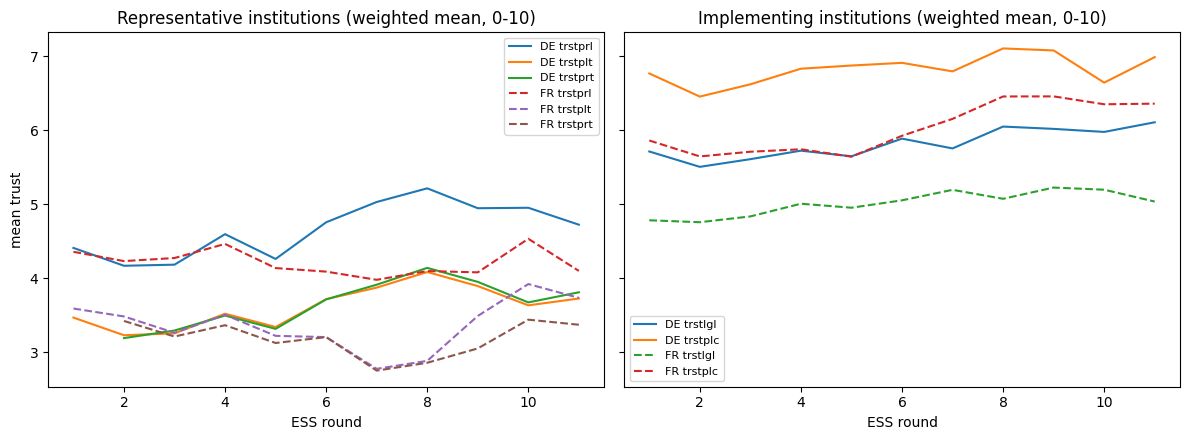

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, items, title in zip(axes, [REP_ITEMS, IMP_ITEMS], ["Representative", "Implementing"]):
    for cntry, style in zip(["DE", "FR"], ["-", "--"]):
        sub = raw_means[raw_means["cntry"] == cntry]
        for item in items:
            ax.plot(
                sub["essround"],
                sub[f"{item}_weighted"],
                style,
                label=f"{cntry} {item}",
            )
    ax.set_title(f"{title} institutions (weighted mean, 0-10)")
    ax.set_xlabel("ESS round")
    ax.legend(fontsize=8)
axes[0].set_ylabel("mean trust")
fig.tight_layout()

### Analysis table

Drop respondents missing any of the 5 items in scope (this mainly removes round 1, where
`trstprt` wasn't asked), then build a single `country x round` group index for the model.

In [17]:
analysis = df.dropna(subset=TRUST_ITEMS).copy()
print(f"Rows before dropna: {len(df)}, after: {len(analysis)}")
print(analysis.groupby("cntry").size())

for col in TRUST_ITEMS:
    analysis[col] = analysis[col].astype(int)

cntry_round = pd.Series(list(zip(analysis["cntry"], analysis["essround"])), index=analysis.index)
analysis["group"], group_labels = pd.factorize(cntry_round, sort=True)
group_labels = pd.MultiIndex.from_tuples(group_labels, names=["cntry", "essround"])
n_groups = len(group_labels)
country_of_group = (group_labels.get_level_values("cntry") == "FR").astype(int)
# country_of_group: 0 = DE, 1 = FR
print(f"n_groups={n_groups}")
group_labels[:5]

Rows before dropna: 57654, after: 51535
cntry
DE    32782
FR    18753
dtype: int64
n_groups=20


MultiIndex([('DE', 2),
            ('DE', 3),
            ('DE', 4),
            ('DE', 5),
            ('DE', 6)],
           names=['cntry', 'essround'])

## Part 2 — Minimal PyMC model

Two respondent-level latent trust dimensions (`trust_rep`, `trust_imp`), each measured by an
ordinal graded-response model, with a hierarchical mean per `(country, round)` cell.

**Deviations from a naive single-factor / shared-cutpoints model, and why:**
- *Two dimensions, not one.* Collapsing all 5 items into one latent trust score would erase
  the paper's central finding that representative and implementing trust move differently.
- *Item-specific cutpoints.* Sharing one cutpoints vector across items (as in a single-factor
  draft) implicitly assumes parliament/politicians/parties/police/legal-system all have the
  same response base rate — empirically false (trust in police runs much higher than trust in
  politicians). Each item gets its own ordered cutpoints here.
- *Scale identification.* `trust_dim ~ Normal(mu_group, 1)` fixes the latent scale (sd=1); the
  weakly-informative prior centering cutpoints on `anchor = np.arange(10) - 4.5` resolves the
  residual location non-identifiability between the group means and the cutpoints. No
  reference-country constraint (e.g. `alpha[0] = 0`) is needed on top of that.
- *Known simplification:* `trust_rep` and `trust_imp` are modeled as independent latents —
  there is no cross-dimension correlation term. In reality the two are likely correlated at
  the respondent level; that's deferred to a later iteration, not an oversight.
- *Country × round, not a full dynamic model.* The paper fits a dynamic (random-walk) latent
  trait over time. Here, a hierarchical mean per `(country, round)` cell (partially pooled
  toward each country's overall level) is the minimal stand-in — it gives a trend per country
  without building the smoothing/state-space machinery.

In [18]:
import pymc as pm
import arviz as az

# Runtime tiers. Cost scales roughly with n_resp x (draws+tune), since every NUTS
# gradient step touches all ~2 x n_resp respondent-level latents (trust_rep, trust_imp).
# The model only has 20 country x round groups to estimate, so a few thousand
# respondents per country is already enough to pin those means down tightly -- the
# "full" tier mostly sharpens individual-respondent latents nobody is looking at.
#   debug:  ~10s   -- does the model run at all
#   medium: ~1 min -- good enough to sanity-check trends and iterate on model structure
#   full:   ~90 min on this machine -- final confirmatory run only
SAMPLE_SIZE = "medium"  # "debug" | "medium" | "full"

N_PER_COUNTRY = {"debug": 400, "medium": 2000, "full": None}[SAMPLE_SIZE]

if N_PER_COUNTRY is None:
    model_df = analysis.reset_index(drop=True)
else:
    model_df = (
        analysis.groupby("cntry", group_keys=False)
        .apply(lambda g: g.sample(min(N_PER_COUNTRY, len(g)), random_state=0))
        .reset_index(drop=True)
    )

y_rep = model_df[REP_ITEMS].to_numpy()
y_imp = model_df[IMP_ITEMS].to_numpy()
group_idx = model_df["group"].to_numpy()
n_resp = len(model_df)
print(f"n_resp={n_resp}, n_groups used={len(np.unique(group_idx))}")

n_resp=4000, n_groups used=20


In [19]:
anchor = np.arange(10) - 4.5
n_countries = 2

draws, tune, chains = {
    "debug": (300, 300, 2),
    "medium": (1000, 1000, 4),
    "full": (1000, 1000, 4),
}[SAMPLE_SIZE]

with pm.Model() as model:
    # --- structural part: hierarchical mean per country x round, per dimension ---
    alpha_rep = pm.Normal("alpha_rep", 0, 1, shape=n_countries)
    alpha_imp = pm.Normal("alpha_imp", 0, 1, shape=n_countries)

    sigma_round_rep = pm.HalfNormal("sigma_round_rep", 0.5)
    sigma_round_imp = pm.HalfNormal("sigma_round_imp", 0.5)

    z_rep = pm.Normal("z_rep", 0, 1, shape=n_groups)
    z_imp = pm.Normal("z_imp", 0, 1, shape=n_groups)
    mu_rep_group = pm.Deterministic(
        "mu_rep_group", alpha_rep[country_of_group] + z_rep * sigma_round_rep
    )
    mu_imp_group = pm.Deterministic(
        "mu_imp_group", alpha_imp[country_of_group] + z_imp * sigma_round_imp
    )

    # --- respondent-level latent trust ---
    trust_rep = pm.Normal("trust_rep", mu_rep_group[group_idx], 1, shape=n_resp)
    trust_imp = pm.Normal("trust_imp", mu_imp_group[group_idx], 1, shape=n_resp)

    # --- measurement part: item-specific cutpoints ---
    cut_rep = pm.Normal(
        "cut_rep",
        mu=anchor,
        sigma=1,
        shape=(len(REP_ITEMS), 10),
        transform=pm.distributions.transforms.ordered,
        initval=np.tile(anchor, (len(REP_ITEMS), 1)),
    )
    cut_imp = pm.Normal(
        "cut_imp",
        mu=anchor,
        sigma=1,
        shape=(len(IMP_ITEMS), 10),
        transform=pm.distributions.transforms.ordered,
        initval=np.tile(anchor, (len(IMP_ITEMS), 1)),
    )

    for j, name in enumerate(REP_ITEMS):
        pm.OrderedLogistic(name, eta=trust_rep, cutpoints=cut_rep[j], observed=y_rep[:, j])
    for j, name in enumerate(IMP_ITEMS):
        pm.OrderedLogistic(name, eta=trust_imp, cutpoints=cut_imp[j], observed=y_imp[:, j])

    idata = pm.sample(draws, tune=tune, chains=chains, cores=chains, target_accept=0.8, nuts_sampler="nutpie")

NUTS[nutpie]: [alpha_rep, alpha_imp, sigma_round_rep, sigma_round_imp, z_rep, z_imp, trust_rep, trust_imp, cut_rep, cut_imp]


Output()

## Diagnostics

In [20]:
az.summary(
    idata,
    var_names=["alpha_rep", "alpha_imp", "sigma_round_rep", "sigma_round_imp"],
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha_rep[0],-1.08,0.22,-1.4,-0.72,42,101,1.07,0.034,0.013
alpha_rep[1],-1.53,0.22,-1.9,-1.2,37,62,1.08,0.035,0.013
alpha_imp[0],1.01,0.23,0.62,1.4,44,84,1.10,0.036,0.011
alpha_imp[1],0.24,0.23,-0.13,0.59,35,41,1.12,0.039,0.013
sigma_round_rep,0.391,0.074,0.29,0.52,619,1234,1.01,0.003,0.0017
sigma_round_imp,0.333,0.068,0.24,0.45,893,1410,1.00,0.0023,0.0018


In [21]:
n_divergent = int(idata.sample_stats["diverging"].sum())
print(f"divergences: {n_divergent}")

divergences: 0


### Posterior country x round trust vs. the raw weighted means

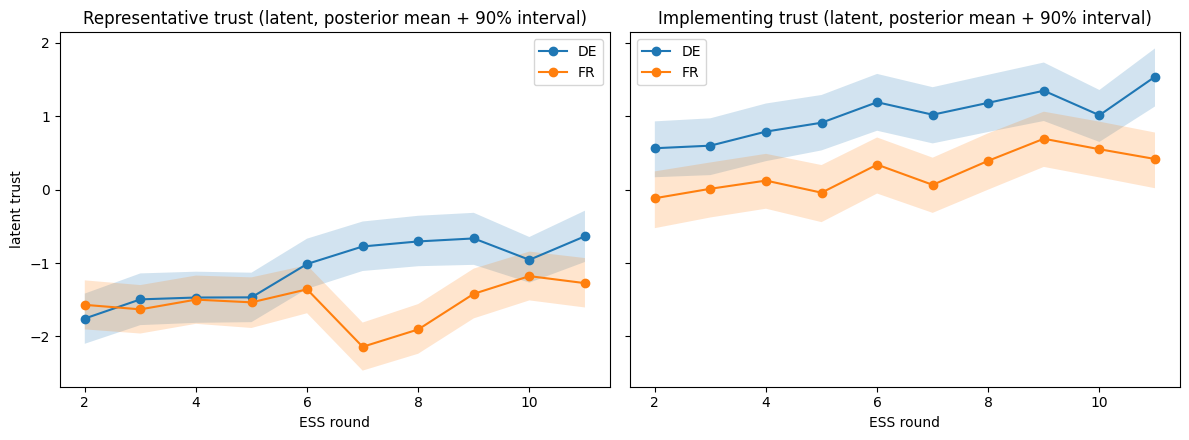

In [22]:
mu_rep_summary = az.summary(idata, var_names=["mu_rep_group"], ci_prob=0.9)
mu_imp_summary = az.summary(idata, var_names=["mu_imp_group"], ci_prob=0.9)

post = group_labels.to_frame(index=False)
post["mu_rep"] = mu_rep_summary["mean"].to_numpy()
post["mu_rep_lo"] = mu_rep_summary["eti90_lb"].to_numpy()
post["mu_rep_hi"] = mu_rep_summary["eti90_ub"].to_numpy()
post["mu_imp"] = mu_imp_summary["mean"].to_numpy()
post["mu_imp_lo"] = mu_imp_summary["eti90_lb"].to_numpy()
post["mu_imp_hi"] = mu_imp_summary["eti90_ub"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, dim, title in zip(axes, ["rep", "imp"], ["Representative", "Implementing"]):
    for cntry in ["DE", "FR"]:
        sub = post[post["cntry"] == cntry].sort_values("essround")
        ax.plot(sub["essround"], sub[f"mu_{dim}"], marker="o", label=cntry)
        ax.fill_between(
            sub["essround"], sub[f"mu_{dim}_lo"], sub[f"mu_{dim}_hi"], alpha=0.2
        )
    ax.set_title(f"{title} trust (latent, posterior mean + 90% interval)")
    ax.set_xlabel("ESS round")
    ax.legend()
axes[0].set_ylabel("latent trust")
fig.tight_layout()

### Interpretation

*(Fill in once the full-data run completes.)* Compare the direction of the DE and FR trends
for representative vs. implementing trust against the paper's global finding — declining
trust in representative institutions, stable-or-rising trust in implementing institutions.
Note explicitly where this 2-country, 5-item, non-dynamic model agrees or disagrees, without
overclaiming: it has no regional resolution, no vote linkage, and pools rounds toward a
country mean rather than smoothing a proper time series.